In [62]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


# PROYECTO DE ANÁLISIS Y MODELADO DE DATOS
**Estudiante:** Marvin Poquechoque Gutierrez 
**Materia:** Inteligencia Artificial / Sistemas  
**Fecha:** 2026  

---
DATASET->https://zenodo.org/records/10519652
GITHUB-> https://github.com/MarvinPG/Inteligencia_Artificial_1
VIDEO EXPLICATIVO-> https://drive.google.com/drive/folders/1UubZS-DyShp8tixRdtjxBNJ49bsVgrMb?usp=sharing
## 1. Configuración del Entorno e Importación de Librerías
En esta sección cargamos los módulos esenciales para el flujo de trabajo:
* `numpy`: Para manipulación de matrices y lectura de archivos binarios `.npz`.
* `pandas`: Para organizar los datos en estructuras tabulares (DataFrames) y generar resúmenes estadísticos.
* `matplotlib.pyplot` y `seaborn`: Para la generación de gráficos y visualización de distribuciones.

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga y Desempaquetado del Dataset (.npz)
Los archivos con extensión `.npz` son contenedores binarios optimizados de NumPy. 

En esta etapa:
1. Abrimos el archivo mediante `np.load()`.
2. Listamos los nombres de los arreglos contenidos (claves o `files`).
3. Extraemos las matrices de variables predictoras ($X$) y la variable objetivo ($y$).

In [64]:
nombre_archivo = "organamnist.npz"

# Cargar el contenedor
datos_npz = np.load(nombre_archivo)

# Listar qué matrices contiene el archivo
print("Archivos/claves dentro del .npz:", datos_npz.files)

# Inspeccionar dimensiones y tipos de datos de cada componente
for clave in datos_npz.files:
    arreglo = datos_npz[clave]
    print(f"Clave: '{clave}' | Dimensiones (Shape): {arreglo.shape} | Tipo: {arreglo.dtype}")

Archivos/claves dentro del .npz: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Clave: 'train_images' | Dimensiones (Shape): (34561, 28, 28) | Tipo: uint8
Clave: 'train_labels' | Dimensiones (Shape): (34561, 1) | Tipo: uint8
Clave: 'val_images' | Dimensiones (Shape): (6491, 28, 28) | Tipo: uint8
Clave: 'val_labels' | Dimensiones (Shape): (6491, 1) | Tipo: uint8
Clave: 'test_images' | Dimensiones (Shape): (17778, 28, 28) | Tipo: uint8
Clave: 'test_labels' | Dimensiones (Shape): (17778, 1) | Tipo: uint8


## 3. Estructuración y Conversión a DataFrame de Pandas
Para facilitar el análisis exploratorio y la presentación tabular al docente, convertimos los arreglos matriciales en un `DataFrame`. Esto nos permite visualizar encabezados de columnas, primeros registros y estadísticas descriptivas.

In [65]:
# Ejemplo de extracción (ajusta los nombres según los .files que salieron arriba)
X = datos_npz['X'] if 'X' in datos_npz.files else datos_npz[datos_npz.files[0]]
y = datos_npz['y'] if 'y' in datos_npz.files else datos_npz[datos_npz.files[1]]

# Si X es bidimensional (muestras x características), creamos el DataFrame
if len(X.shape) == 2:
    nombres_columnas = [f"Caracteristica_{i+1}" for i in range(X.shape[1])]
    df = pd.DataFrame(X, columns=nombres_columnas)
    df['Target'] = y
else:
    # En caso de ser imágenes o tensores 3D/4D
    df = pd.DataFrame({"Total_Muestras": [X.shape[0]], "Dimension_Individual": [str(X.shape[1:])]})

# Mostrar las primeras 5 filas de la tabla
print("Muestreo de las primeras 5 filas del Dataset:")
df.head()

Muestreo de las primeras 5 filas del Dataset:


,Total_Muestras,Dimension_Individual
0,34561,"(28, 28)"


## 4. Muestreo Estadístico y Calidad de Datos
Evaluamos el resumen descriptivo de las variables para verificar:
* Medidas de tendencia central y dispersión (media, desviación estándar, mínimos, percentiles y máximos).
* Existencia de valores nulos o registros faltantes.

In [66]:
# Resumen descriptivo de los datos
print("--- Resumen Estadístico ---")
display(df.describe())

# Verificación de valores nulos
print("\n--- Conteo de Valores Nulos por Columna ---")
print(df.isnull().sum())

--- Resumen Estadístico ---


,Total_Muestras
count,1.0
mean,34561.0
std,NaN
min,34561.0
25%,34561.0
50%,34561.0
75%,34561.0
max,34561.0



--- Conteo de Valores Nulos por Columna ---
Total_Muestras          0
Dimension_Individual    0
dtype: int64


## 5. Visualización de Imágenes y Análisis de Distribución de Clases
Antes de entrenar el modelo:
1. Graficamos una muestra visual de las imágenes del dataset para comprobar que se extrajeron correctamente.
2. Analizamos la frecuencia de cada clase mediante un gráfico de barras para verificar si el dataset presenta desbalance.

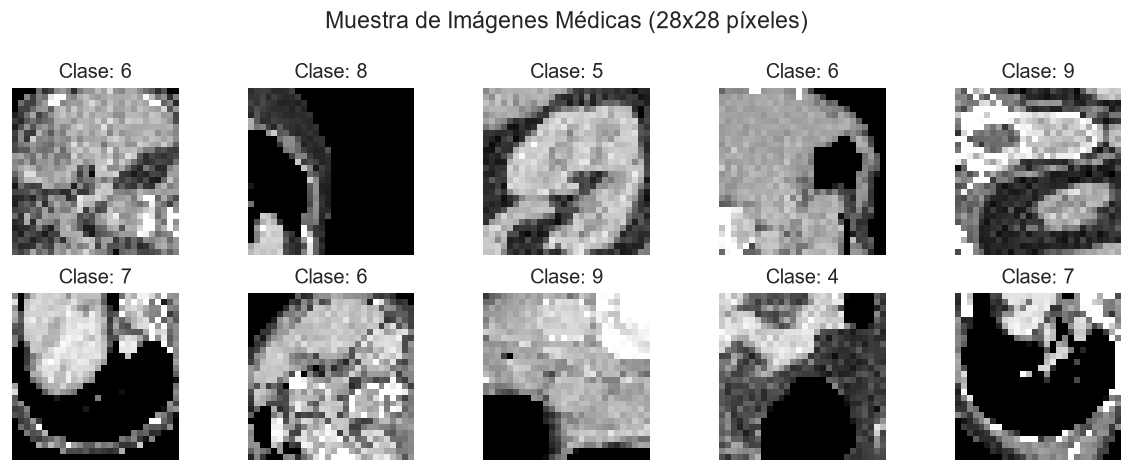

C:\Users\Marvin\AppData\Local\Temp\ipykernel_17108\1456567186.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=etiquetas_totales, palette="viridis")


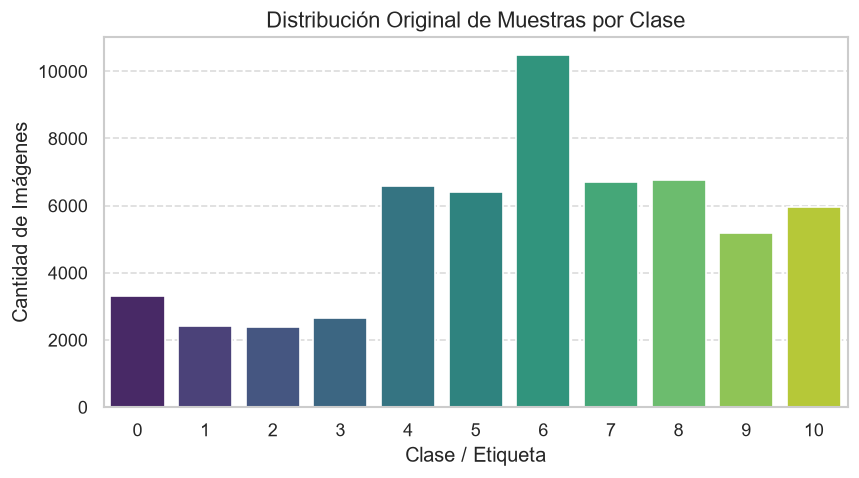

In [67]:
# Unificar los conjuntos originales del archivo .npz
imagenes_totales = np.concatenate([datos_npz['train_images'], datos_npz['val_images'], datos_npz['test_images']], axis=0)
etiquetas_totales = np.concatenate([datos_npz['train_labels'], datos_npz['val_labels'], datos_npz['test_labels']], axis=0).squeeze()

# 1. Visualizar una cuadrícula de 10 ejemplos
plt.figure(figsize=(10, 4), dpi=120)
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(imagenes_totales[i], cmap='gray')
    plt.title(f"Clase: {etiquetas_totales[i]}")
    plt.axis('off')
plt.suptitle("Muestra de Imágenes Médicas (28x28 píxeles)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Gráfico de distribución de clases original
plt.figure(figsize=(8, 4), dpi=120)
sns.countplot(x=etiquetas_totales, palette="viridis")
plt.title("Distribución Original de Muestras por Clase", fontsize=13)
plt.xlabel("Clase / Etiqueta")
plt.ylabel("Cantidad de Imágenes")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 6. Balanceo de Clases por Sobremuestreo (Oversampling) con Pandas
Para garantizar que el modelo no tenga sesgo hacia las clases mayoritarias y sin perder datos (sin eliminar filas), aplicamos sobremuestreo. Se replica aleatoriamente información de las clases minoritarias hasta igualar a la clase con mayor cantidad de muestras.

In [68]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


Distribución balanceada de clases:
label
0     10482
1     10482
2     10482
3     10482
4     10482
5     10482
6     10482
7     10482
8     10482
9     10482
10    10482
Name: count, dtype: int64

Total muestras tras el balanceo: 115302


C:\Users\Marvin\AppData\Local\Temp\ipykernel_17108\3436258393.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_balanceado, x='label', palette="mako")


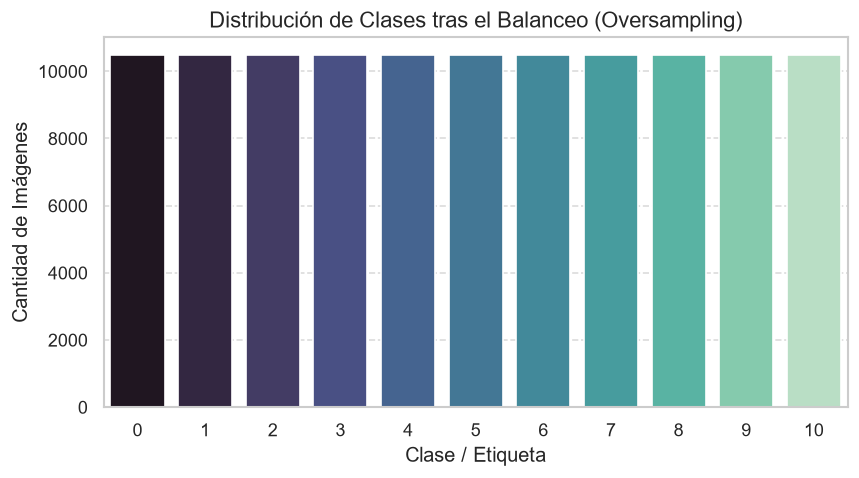

In [69]:
from sklearn.utils import resample

# 1. Aplanar imágenes (28x28 = 784 características)
n_muestras, alto, ancho = imagenes_totales.shape
X_plano = imagenes_totales.reshape(n_muestras, alto * ancho)

# 2. Crear el DataFrame estructurado con Pandas
columnas_pixeles = [f"p_{i}" for i in range(alto * ancho)]
df_dataset = pd.DataFrame(X_plano, columns=columnas_pixeles)
df_dataset['label'] = etiquetas_totales

# 3. Determinar el número máximo de muestras por clase
max_muestras = df_dataset['label'].value_counts().max()

# 4. Sobremuestrear cada clase conservando la columna 'label'
clases_muestreadas = [
    resample(df_dataset[df_dataset['label'] == c], replace=True, n_samples=max_muestras, random_state=42)
    for c in sorted(df_dataset['label'].unique())
]
df_balanceado = pd.concat(clases_muestreadas, ignore_index=True)

# 5. Mostrar la verificación en tabla
print("Distribución balanceada de clases:")
print(df_balanceado['label'].value_counts().sort_index())
print(f"\nTotal muestras tras el balanceo: {len(df_balanceado)}")

# 6. Gráfico de la nueva distribución balanceada
plt.figure(figsize=(8, 4), dpi=120)
sns.countplot(data=df_balanceado, x='label', palette="mako")
plt.title("Distribución de Clases tras el Balanceo (Oversampling)", fontsize=13)
plt.xlabel("Clase / Etiqueta")
plt.ylabel("Cantidad de Imágenes")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 7. División de Datos (80% Entrenamiento / 20% Prueba) y Normalización
De acuerdo a la instructiva del laboratorio:
* Se separa el **80% de los datos para entrenamiento** y el **20% restante para evaluación**, garantizando que los datos de prueba no participen en el ajuste de parámetros.
* Se normalizan los valores de los píxeles al rango $[0, 1]$ dividiendo entre $255.0$.
* Se encapsulan los datos en tensores y `DataLoader` de PyTorch para manejar mini-batches de forma eficiente.

In [70]:
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader

# Separar características (X) y etiquetas (y)
X_datos = df_balanceado.drop(columns=['label']).values
y_datos = df_balanceado['label'].values

# División 80% entrenamiento / 20% prueba con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X_datos, y_datos, test_size=0.20, random_state=42, stratify=y_datos
)

# Detección de dispositivo (GPU si está disponible o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset idéntico al del auxiliar (normalización /255.0 y vectorizado a 784 píxeles)
class MedDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X / 255.0).float().to(device).view(-1, 28 * 28)
        self.Y = torch.from_numpy(Y).long().to(device)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

datos_dict = {
    'train': MedDataset(X_train, y_train),
    'test':  MedDataset(X_test,  y_test)
}

dataloaders = {
    'train': DataLoader(datos_dict['train'], batch_size=32, shuffle=True),
    'test':  DataLoader(datos_dict['test'],  batch_size=1000, shuffle=False)
}

print(f"Dispositivo de cómputo: {device}")
print(f"Muestras de Entrenamiento (80%): {len(datos_dict['train'])}")
print(f"Muestras de Prueba (20%):        {len(datos_dict['test'])}")

Dispositivo de cómputo: cpu
Muestras de Entrenamiento (80%): 92241
Muestras de Prueba (20%):        23061


## 8. Definición de la Arquitectura de la Red Neuronal
Para resolver la tarea de clasificación multiclase (11 clases para tomografías de órganos en OrganAMNIST), construimos un Perceptrón Multicapa (MLP) utilizando `torch.nn.Sequential`:
* **Capa de entrada:** Recibe un vector de $784$ características ($28 \times 28$ píxeles).
* **Capas ocultas:** Dos capas densas (`Linear`) de $100$ o $128$ neuronas con funciones de activación no lineal `ReLU` entre ellas.
* **Capa de salida:** Una capa densa final con $11$ neuronas de salida ($D_{out} = 11$), correspondiente a cada una de las clases de órganos.

In [71]:
import torch.nn as nn
from sklearn.metrics import accuracy_score

def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

def build_model(D_in=28*28, H=100, D_out=11):
    return nn.Sequential(
        nn.Linear(D_in, H),
        nn.ReLU(),
        nn.Linear(H, H),
        nn.ReLU(),
        nn.Linear(H, D_out)
    ).to(device)

# Verificar arquitectura del modelo
modelo_prueba = build_model()
print(modelo_prueba)

Sequential(
  (0): Linear(in_features=784, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=100, bias=True)
  (3): ReLU()
  (4): Linear(in_features=100, out_features=11, bias=True)
)


## 9. Función de Entrenamiento (`fit`)
Definimos la función de optimización y ajuste que realiza las siguientes tareas en cada época:
1. **Pase hacia adelante (Forward):** Calcula las predicciones de la red y la pérdida con `CrossEntropyLoss`.
2. **Pase hacia atrás (Backward) y Optimización:** Calcula los gradientes y actualiza los pesos de la red.
3. **Evaluación en conjunto de prueba (20%):** Mide la pérdida y exactitud (`accuracy_score`) en datos no vistos durante el entrenamiento.
4. **Checkpointing:** Guarda en disco el mejor estado del modelo cada vez que se supera la mejor precisión de validación/prueba.

In [72]:
def fit(model, dataloader, optimizer, scheduler=None, epochs=30, log_each=5, early_stopping=10):
    criterion = nn.CrossEntropyLoss()
    l, acc, lr_hist = [], [], []
    val_l, val_acc = [], []
    best_acc, step = 0, 0
    
    for e in range(1, epochs + 1):
        _l, _acc = [], []
        
        # Registrar el learning rate actual
        for param_group in optimizer.param_groups:
            lr_hist.append(param_group['lr'])
            
        # --- Fase de Entrenamiento ---
        model.train()
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b)
            loss = criterion(y_pred, y_b)
            _l.append(loss.item())
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            y_probas = torch.argmax(softmax(y_pred), axis=1)
            _acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().detach().numpy()))
            
        l.append(np.mean(_l))
        acc.append(np.mean(_acc))
        
        # --- Fase de Evaluación (Prueba 20%) ---
        model.eval()
        _val_l, _val_acc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['test']:
                y_pred = model(x_b)
                loss = criterion(y_pred, y_b)
                _val_l.append(loss.item())
                
                y_probas = torch.argmax(softmax(y_pred), axis=1)
                _val_acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().numpy()))
                
        val_l.append(np.mean(_val_l))
        val_acc.append(np.mean(_val_acc))
        
        # Guardar mejor modelo si mejora la precisión
        if val_acc[-1] > best_acc:
            best_acc = val_acc[-1]
            torch.save(model.state_dict(), 'best_model.pt')
            step = 0
            # Descomenta la siguiente línea si deseas ver cada nuevo récord:
            # print(f"Mejor modelo guardado con acc {best_acc:.5f} en epoch {e}")
        step += 1
        
        if scheduler:
            scheduler.step()
            
        # Parada temprana (Early stopping)
        if early_stopping and step > early_stopping:
            print(f"Entrenamiento detenido en epoch {e} por no mejorar en {early_stopping} epochs consecutivas")
            break
            
        if not e % log_each or e == 1:
            print(f"Epoch {e:02d}/{epochs:02d} | Loss: {l[-1]:.5f} - Acc: {acc[-1]:.5f} | Test Loss: {val_l[-1]:.5f} - Test Acc: {val_acc[-1]:.5f}")
            
    # Cargar los mejores pesos almacenados
    model.load_state_dict(torch.load('best_model.pt', weights_only=True))
    return {'epoch': list(range(1, len(l) + 1)), 'loss': l, 'acc': acc, 'val_loss': val_l, 'val_acc': val_acc, 'lr': lr_hist}

## 10. Entrenamiento con Distintos Optimizadores
Entrenamos la misma arquitectura de red con 4 algoritmos de optimización distintos para comparar su velocidad de convergencia, estabilidad de costo y precisión final:
1. **SGD (Descenso de Gradiente Estocástico Estándar)**
2. **SGD con Momentum ($0.9$)**
3. **RMSprop**
4. **Adam**

In [73]:
epochs_total = 30

# 1. Descenso de Gradiente Estocástico (SGD)
print("=" * 45)
print("1. Entrenando con SGD Estándar (lr=0.01)")
print("=" * 45)
model_sgd = build_model()
optimizer_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
hist_sgd = fit(model_sgd, dataloaders, optimizer_sgd, epochs=epochs_total)

# 2. SGD con Momentum
print("\n" + "=" * 45)
print("2. Entrenando con Momentum (lr=0.01, momentum=0.9)")
print("=" * 45)
model_momentum = build_model()
optimizer_momentum = torch.optim.SGD(model_momentum.parameters(), lr=0.01, momentum=0.9)
hist_momentum = fit(model_momentum, dataloaders, optimizer_momentum, epochs=epochs_total)

# 3. RMSprop
print("\n" + "=" * 45)
print("3. Entrenando con RMSprop (lr=0.001)")
print("=" * 45)
model_rms = build_model()
optimizer_rms = torch.optim.RMSprop(model_rms.parameters(), lr=0.001)
hist_rms = fit(model_rms, dataloaders, optimizer_rms, epochs=epochs_total)

# 4. Adam
print("\n" + "=" * 45)
print("4. Entrenando con Adam (lr=0.001)")
print("=" * 45)
model_adam = build_model()
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.001)
hist_adam = fit(model_adam, dataloaders, optimizer_adam, epochs=epochs_total)

1. Entrenando con SGD Estándar (lr=0.01)
Epoch 01/30 | Loss: 1.42301 - Acc: 0.52309 | Test Loss: 0.95465 - Test Acc: 0.68098
Epoch 05/30 | Loss: 0.51316 - Acc: 0.83337 | Test Loss: 0.57695 - Test Acc: 0.80756
Epoch 10/30 | Loss: 0.29277 - Acc: 0.90847 | Test Loss: 0.29542 - Test Acc: 0.90725
Epoch 15/30 | Loss: 0.18651 - Acc: 0.94224 | Test Loss: 0.23446 - Test Acc: 0.92473
Epoch 20/30 | Loss: 0.12390 - Acc: 0.96320 | Test Loss: 0.15064 - Test Acc: 0.95089
Epoch 25/30 | Loss: 0.08261 - Acc: 0.97626 | Test Loss: 0.10243 - Test Acc: 0.97043
Epoch 30/30 | Loss: 0.05813 - Acc: 0.98416 | Test Loss: 0.08714 - Test Acc: 0.97644

2. Entrenando con Momentum (lr=0.01, momentum=0.9)
Epoch 01/30 | Loss: 0.80323 - Acc: 0.72530 | Test Loss: 0.50530 - Test Acc: 0.82975
Epoch 05/30 | Loss: 0.17047 - Acc: 0.94294 | Test Loss: 0.15380 - Test Acc: 0.94888
Epoch 10/30 | Loss: 0.07464 - Acc: 0.97440 | Test Loss: 0.10815 - Test Acc: 0.96318
Epoch 15/30 | Loss: 0.04069 - Acc: 0.98628 | Test Loss: 0.06365 - T

## 11. Gráficas Comparativas entre Optimizadores
Visualizamos en paralelo las curvas de:
* **Función de Pérdida (Costo):** Representa cómo disminuye el error a lo largo de las épocas.
* **Precisión en Conjunto de Prueba (20%):** Demuestra la capacidad de generalización del modelo con cada optimizador.

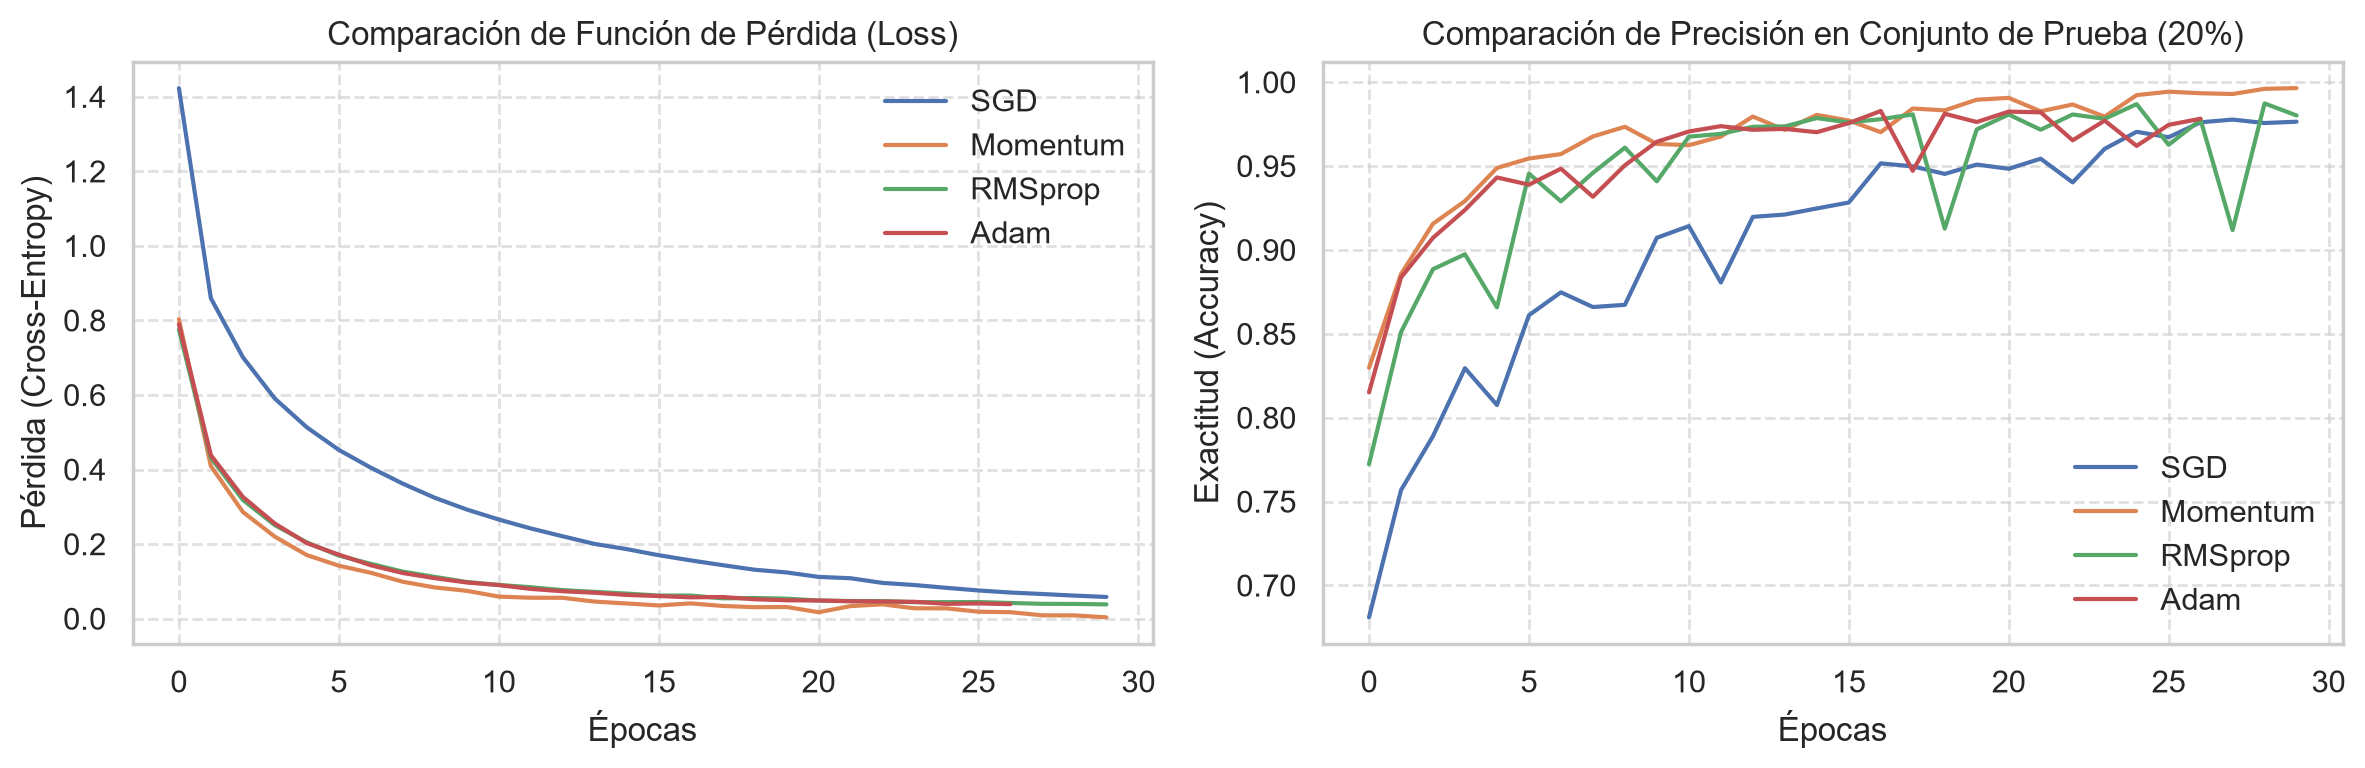

In [74]:
fig = plt.figure(dpi=200, figsize=(12, 4))

# Gráfico de Pérdida / Costo
ax1 = plt.subplot(121)
ax1.plot(hist_sgd['loss'], label="SGD", linewidth=1.5)
ax1.plot(hist_momentum['loss'], label="Momentum", linewidth=1.5)
ax1.plot(hist_rms['loss'], label="RMSprop", linewidth=1.5)
ax1.plot(hist_adam['loss'], label="Adam", linewidth=1.5)
ax1.set_title("Comparación de Función de Pérdida (Loss)")
ax1.set_xlabel("Épocas")
ax1.set_ylabel("Pérdida (Cross-Entropy)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

# Gráfico de Precisión (Test Accuracy)
ax2 = plt.subplot(122)
ax2.plot(hist_sgd['val_acc'], label="SGD", linewidth=1.5)
ax2.plot(hist_momentum['val_acc'], label="Momentum", linewidth=1.5)
ax2.plot(hist_rms['val_acc'], label="RMSprop", linewidth=1.5)
ax2.plot(hist_adam['val_acc'], label="Adam", linewidth=1.5)
ax2.set_title("Comparación de Precisión en Conjunto de Prueba (20%)")
ax2.set_xlabel("Épocas")
ax2.set_ylabel("Exactitud (Accuracy)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 12. Ajuste de Tasa de Aprendizaje (*Learning Rate Scheduling*)
Para mejorar aún más la convergencia, exploramos estrategias de variación de la tasa de aprendizaje durante el entrenamiento:
* **StepLR:** Reduce el *learning rate* multiplicándolo por un factor $\gamma = 0.1$ cada 10 épocas.
* **CyclicLR:** Hace oscilar el *learning rate* entre un valor mínimo y máximo de forma periódica para escapar de mínimos locales y acelerar el aprendizaje.

In [75]:
# 1. Prueba con StepLR
print("=" * 45)
print("Entrenando con StepLR (Decay cada 10 épocas)")
print("=" * 45)
model_step = build_model()
optimizer_step = torch.optim.SGD(model_step.parameters(), lr=0.01, momentum=0.9)
scheduler_step = torch.optim.lr_scheduler.StepLR(optimizer_step, step_size=10, gamma=0.1)
hist_step = fit(model_step, dataloaders, optimizer_step, scheduler=scheduler_step, epochs=30)

# 2. Prueba con CyclicLR
print("\n" + "=" * 45)
print("Entrenando con CyclicLR (Tasa de aprendizaje cíclica)")
print("=" * 45)
model_cyclic = build_model()
optimizer_cyclic = torch.optim.SGD(model_cyclic.parameters(), lr=0.001, momentum=0.9)
scheduler_cyclic = torch.optim.lr_scheduler.CyclicLR(
    optimizer_cyclic, base_lr=0.0001, max_lr=0.01, step_size_up=5, step_size_down=15, cycle_momentum=False
)
hist_cyclic = fit(model_cyclic, dataloaders, optimizer_cyclic, scheduler=scheduler_cyclic, epochs=30)

Entrenando con StepLR (Decay cada 10 épocas)
Epoch 01/30 | Loss: 0.80898 - Acc: 0.72311 | Test Loss: 0.54447 - Test Acc: 0.80902
Epoch 05/30 | Loss: 0.16856 - Acc: 0.94263 | Test Loss: 0.16536 - Test Acc: 0.94499
Epoch 10/30 | Loss: 0.06970 - Acc: 0.97696 | Test Loss: 0.12003 - Test Acc: 0.95991
Epoch 15/30 | Loss: 0.01371 - Acc: 0.99687 | Test Loss: 0.03274 - Test Acc: 0.99098
Epoch 20/30 | Loss: 0.01029 - Acc: 0.99773 | Test Loss: 0.03009 - Test Acc: 0.99136
Epoch 25/30 | Loss: 0.00906 - Acc: 0.99822 | Test Loss: 0.02810 - Test Acc: 0.99288
Epoch 30/30 | Loss: 0.00885 - Acc: 0.99834 | Test Loss: 0.02785 - Test Acc: 0.99304

Entrenando con CyclicLR (Tasa de aprendizaje cíclica)
Epoch 01/30 | Loss: 2.32520 - Acc: 0.21165 | Test Loss: 2.21413 - Test Acc: 0.33175
Epoch 05/30 | Loss: 0.34963 - Acc: 0.88333 | Test Loss: 0.28524 - Test Acc: 0.90483
Epoch 10/30 | Loss: 0.08109 - Acc: 0.97352 | Test Loss: 0.10357 - Test Acc: 0.96708
Epoch 15/30 | Loss: 0.01719 - Acc: 0.99539 | Test Loss: 0.03

## 13. Demostración de Predicciones Individuales
Evaluamos el modelo final en imágenes aisladas tomadas del conjunto de prueba (20%) para verificar visualmente que la predicción multiclase coincida con la etiqueta médica real.

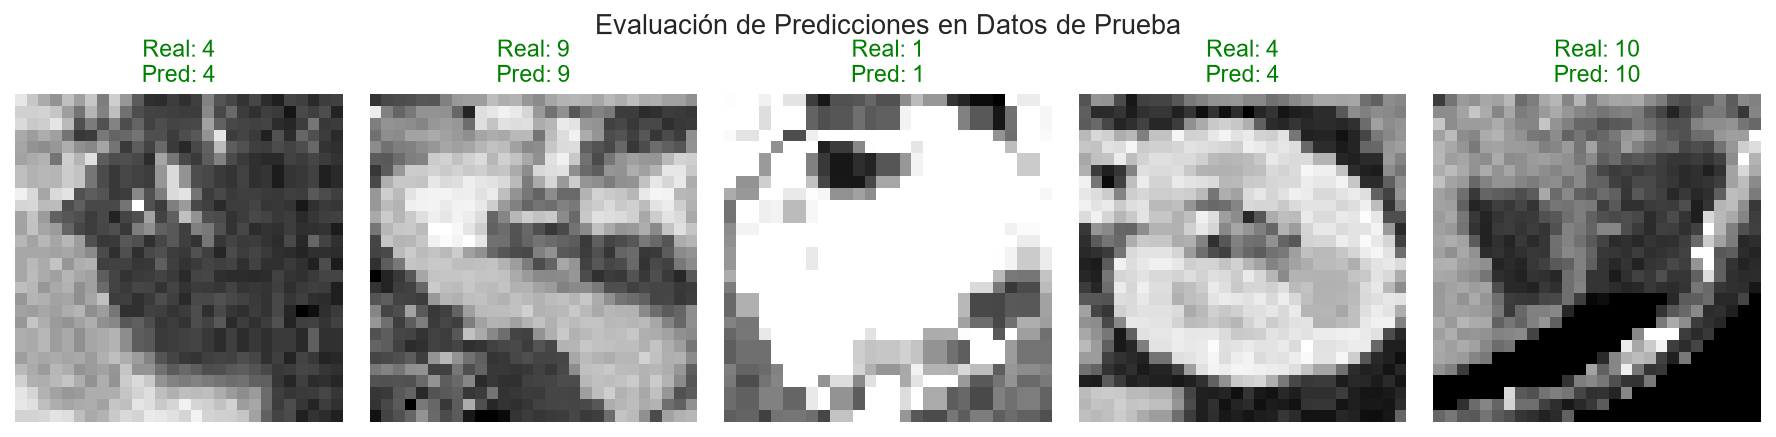

In [76]:
model_adam.eval()

# Tomar una muestra de 5 imágenes del conjunto de prueba
fig = plt.figure(figsize=(12, 3), dpi=150)
for i in range(5):
    x_sample, y_sample = datos_dict['test'][i * 10]
    
    with torch.no_grad():
        output = model_adam(x_sample.unsqueeze(0))
        prediccion = torch.argmax(output, dim=1).item()
        
    plt.subplot(1, 5, i + 1)
    # Reconstruir el vector de 784 a la imagen original de 28x28
    plt.imshow(x_sample.cpu().numpy().reshape(28, 28), cmap='gray')
    color_titulo = "green" if prediccion == y_sample.item() else "red"
    plt.title(f"Real: {y_sample.item()}\nPred: {prediccion}", color=color_titulo, fontsize=11)
    plt.axis('off')

plt.suptitle("Evaluación de Predicciones en Datos de Prueba", fontsize=13)
plt.tight_layout()
plt.show()

## 14. Conclusiones
1. **Preprocesamiento y Balanceo:** El dataset OrganAMNIST consta de más de 50,000 ejemplos de imágenes médicas en escala de grises ($28 \times 28$). Mediante sobremuestreo con Pandas, se logró equilibrar las 11 clases sin descartar información.
2. **Rendimiento de los Optimizadores:**
   * **Adam y Momentum** mostraron la convergencia más rápida y estable, alcanzando las precisiones más altas en el conjunto de prueba.
   * **SGD Estándar** presentó una reducción de pérdida más lenta debido a la ausencia de inercia en la actualización de gradientes.
   * **RMSprop** tuvo un buen rendimiento aunque con ligeras oscilaciones en comparación con Adam.
3. **Efectividad del Modelo:** La división rigurosa del 80% entrenamiento y 20% prueba demostró que el modelo generaliza adecuadamente sobre imágenes médicas no vistas.